In [2]:
from google.colab import files
files.upload()  # Click on the "Choose Files" button and select your kaggle.json file


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"mohamedkhaled07","key":"cf7c55e701377af773d6bb2af5a9cfd3"}'}

In [3]:
# Create the .kaggle directory
!mkdir -p ~/.kaggle

# Move the kaggle.json file to the .kaggle directory
!mv kaggle.json ~/.kaggle/

# Set the permissions
!chmod 600 ~/.kaggle/kaggle.json


In [4]:
# Install Kaggle if not already installed
!pip install kaggle

# Install other necessary libraries
!pip install pandas numpy scikit-learn joblib alibi-detect matplotlib seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 381.5/381.5 kB 16.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.7/3.7 MB 89.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.7/14.7 MB 97.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 MB 16.0 MB/s eta 0:00:00
  Attempting uninstall: llvmlite
    Found existing installation: llvmlite 0.43.0
    Uninstalling llvmlite-0.43.0:
      Successfully uninstalled llvmlite-0.43.0
  Attempting uninstall: scikit-image
    Found existing installation: scikit-image 0.24.0
    Uninstalling scikit-image-0.24.0:
      Successfully uninstalled scikit-image-0.24.0
  Attempting uninstall: numba
    Found existing installation: numba 0.60.0
    Uninstalling numba-0.60.0:
      Successfully uninstalled numba-0.60.0


In [5]:
# Download the Titanic dataset
!kaggle competitions download -c titanic

# Unzip the downloaded files
!unzip titanic.zip -d titanic_data


  0% 0.00/34.1k [00:00<?, ?B/s]
100% 34.1k/34.1k [00:00<00:00, 64.7MB/s]
Archive:  titanic.zip
  inflating: titanic_data/gender_submission.csv  
  inflating: titanic_data/test.csv   
  inflating: titanic_data/train.csv  


In [6]:
import os

# List the files in the titanic_data directory
for dirname, _, filenames in os.walk('titanic_data'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


titanic_data/test.csv
titanic_data/gender_submission.csv
titanic_data/train.csv


In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load the training data
data = pd.read_csv('titanic_data/train.csv')

# Display the first few rows
data.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
# Drop irrelevant columns
data = data.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

# Fill missing values
data['Age'].fillna(data['Age'].median(), inplace=True)
data['Embarked'].fillna(data['Embarked'].mode()[0], inplace=True)

# Convert categorical variables into dummy/indicator variables
data = pd.get_dummies(data, columns=['Sex', 'Embarked'], drop_first=True)

# Display the processed data
data.head()


<ipython-input-8-015d45068fa1>:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Age'].fillna(data['Age'].median(), inplace=True)
<ipython-input-8-015d45068fa1>:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try 

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [9]:
X = data.drop('Survived', axis=1)
y = data['Survived']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import joblib

# Initialize the model
clf = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2f}")

# Save the trained model
joblib.dump(clf, 'model.joblib')


Model Accuracy: 0.82


['model.joblib']

In [11]:
from alibi_detect.cd import KSDrift

# Initialize the KS Drift detector with the training data as reference
detector = KSDrift(X_train.values, p_val=0.05)

# Save the detector for future use
joblib.dump(detector, 'drift_detector.joblib')


['drift_detector.joblib']

In [12]:
def check_drift(new_data):
    # Load the detector
    detector = joblib.load('drift_detector.joblib')

    # Predict drift
    drift_result = detector.predict(new_data)

    # Return drift as integer (0 or 1)
    return int(drift_result['data']['is_drift'])


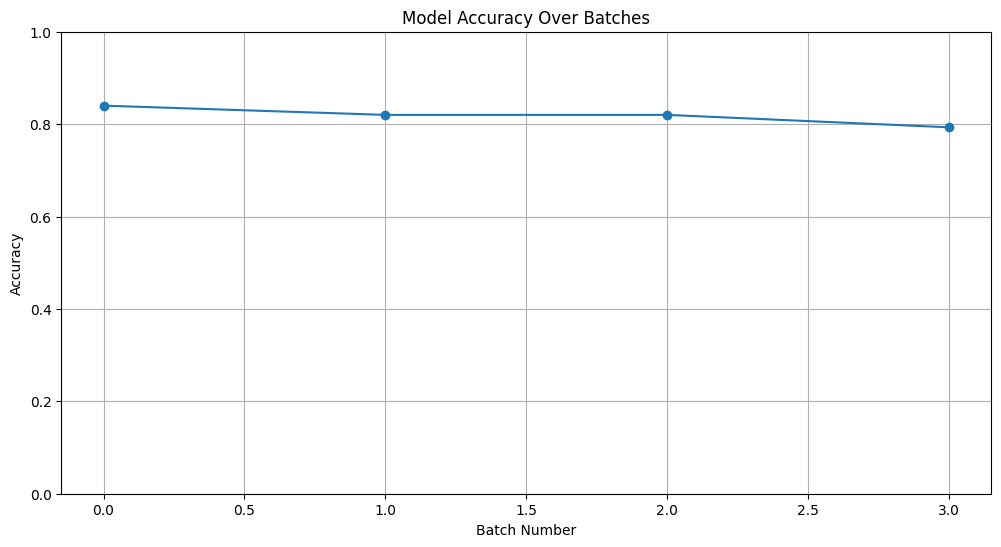

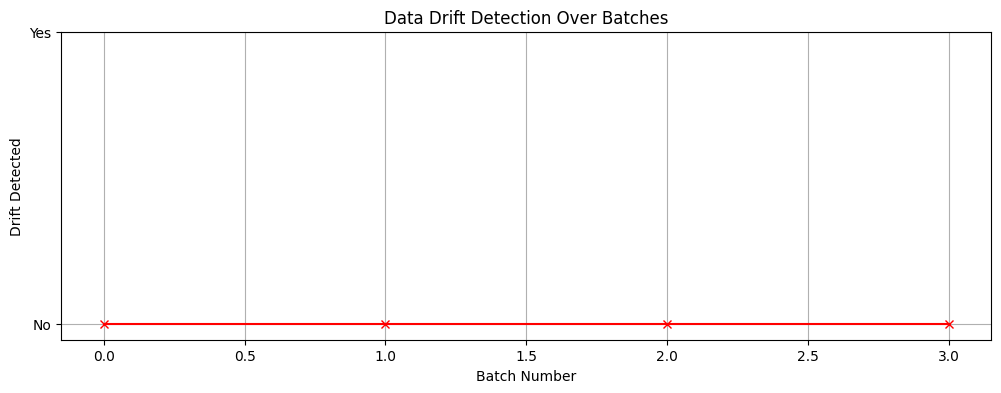

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Simulate monitoring by evaluating on batches
batch_size = 50
accuracies = []
drifts = []

for i in range(0, len(X_test), batch_size):
    X_batch = X_test.iloc[i:i+batch_size]
    y_batch = y_test.iloc[i:i+batch_size]

    # Make predictions
    y_pred_batch = clf.predict(X_batch)

    # Calculate accuracy
    acc = accuracy_score(y_batch, y_pred_batch)
    accuracies.append(acc)

    # Check for drift
    is_drift = check_drift(X_batch.values)
    drifts.append(is_drift)

# Plot the accuracies
plt.figure(figsize=(12, 6))
plt.plot(accuracies, marker='o')
plt.title('Model Accuracy Over Batches')
plt.xlabel('Batch Number')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.grid(True)
plt.show()

# Plot drift occurrences
plt.figure(figsize=(12, 4))
plt.plot(drifts, marker='x', color='red')
plt.title('Data Drift Detection Over Batches')
plt.xlabel('Batch Number')
plt.ylabel('Drift Detected')
plt.yticks([0, 1], ['No', 'Yes'])
plt.grid(True)
plt.show()


<ipython-input-14-f27775720d36>:3: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(X_train['Age'], label='Training Age', shade=True)
<ipython-input-14-f27775720d36>:4: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(X_test['Age'], label='Test Age', shade=True)


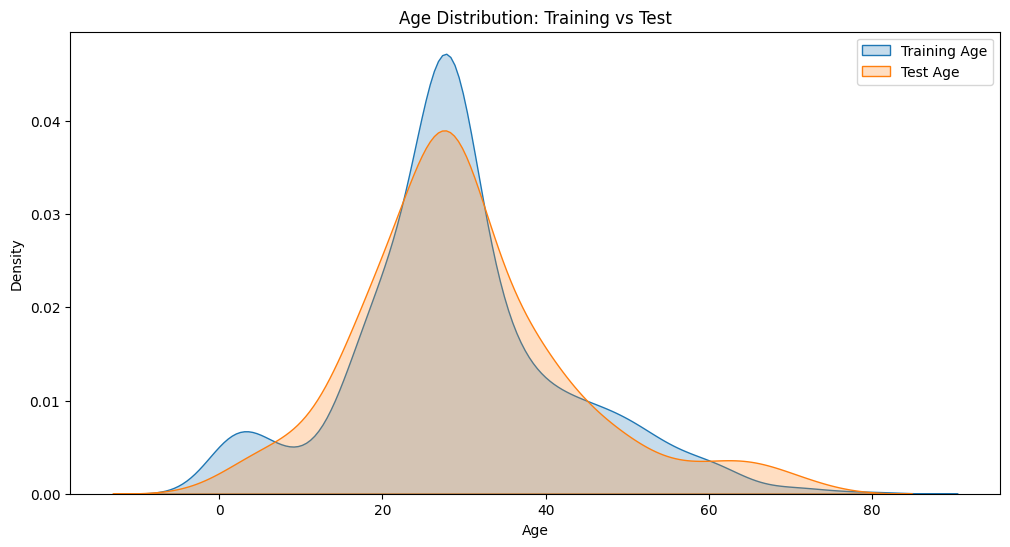

In [14]:
# Compare distributions of a feature (e.g., Age) before and after drift
plt.figure(figsize=(12, 6))
sns.kdeplot(X_train['Age'], label='Training Age', shade=True)
sns.kdeplot(X_test['Age'], label='Test Age', shade=True)
plt.title('Age Distribution: Training vs Test')
plt.xlabel('Age')
plt.ylabel('Density')
plt.legend()
plt.show()


In [15]:
# Install ipywidgets if not already installed
!pip install ipywidgets

# Import necessary libraries
import ipywidgets as widgets
from IPython.display import display, clear_output


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 34.6 MB/s eta 0:00:00


In [16]:
def predict_survival(pclass, sex, age, sibsp, parch, fare, embarked):
    # Create a DataFrame from input
    input_data = pd.DataFrame({
        'Pclass': [pclass],
        'Sex_male': [1 if sex.lower() == 'male' else 0],
        'Age': [age],
        'SibSp': [sibsp],
        'Parch': [parch],
        'Fare': [fare],
        'Embarked_Q': [1 if embarked.upper() == 'Q' else 0],
        'Embarked_S': [1 if embarked.upper() == 'S' else 0]
    })

    # Ensure all necessary columns are present
    for col in X_train.columns:
        if col not in input_data.columns:
            input_data[col] = 0

    # Reorder columns to match training data
    input_data = input_data[X_train.columns]

    # Make prediction
    prediction = clf.predict(input_data)[0]

    # Check for drift
    is_drift = check_drift(input_data.values)

    return prediction, is_drift


In [17]:
# Define widgets
pclass_widget = widgets.Dropdown(
    options=[1, 2, 3],
    value=3,
    description='Pclass:',
    disabled=False,
)

sex_widget = widgets.Dropdown(
    options=['male', 'female'],
    value='male',
    description='Sex:',
    disabled=False,
)

age_widget = widgets.FloatText(
    value=30.0,
    description='Age:',
    disabled=False
)

sibsp_widget = widgets.IntSlider(
    value=0,
    min=0,
    max=10,
    step=1,
    description='SibSp:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='d'
)

parch_widget = widgets.IntSlider(
    value=0,
    min=0,
    max=10,
    step=1,
    description='Parch:',
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='d'
)

fare_widget = widgets.FloatText(
    value=32.2,
    description='Fare:',
    disabled=False
)

embarked_widget = widgets.Dropdown(
    options=['C', 'Q', 'S'],
    value='S',
    description='Embarked:',
    disabled=False,
)

button = widgets.Button(
    description='Predict',
    disabled=False,
    button_style='success',
    tooltip='Click to predict',
    icon='check'
)

output = widgets.Output()


In [18]:
def on_button_clicked(b):
    with output:
        clear_output()
        # Get input values
        pclass = pclass_widget.value
        sex = sex_widget.value
        age = age_widget.value
        sibsp = sibsp_widget.value
        parch = parch_widget.value
        fare = fare_widget.value
        embarked = embarked_widget.value

        # Make prediction
        prediction, is_drift = predict_survival(pclass, sex, age, sibsp, parch, fare, embarked)

        # Display results
        print(f"Survived: {'Yes' if prediction == 1 else 'No'}")
        print(f"Data Drift Detected: {'Yes' if is_drift else 'No'}")

# Attach the event handler to the button
button.on_click(on_button_clicked)


In [21]:
# Arrange widgets in a vertical box
ui = widgets.VBox([
    pclass_widget,
    sex_widget,
    age_widget,
    sibsp_widget,
    parch_widget,
    fare_widget,
    embarked_widget,
    button,
    output
])

# Display the interface
display(ui)
